In [49]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import json

In [50]:
#初始化参数
torch.manual_seed(1337)
batch_size = 4
block_size = 64
n_embd = 32
n_head = 4
n_layer = 2
dropout = 0.0

In [51]:
# 读取 JSONL 文件
records = []
with open("data.jsonl", "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

# print(json.dumps(records[:10], ensure_ascii=False, indent=4))

# 把一轮问答转换为模型学习的文本
def format_record(record):
    messages = record["messages"]
    question = messages[0]["content"]
    answer = messages[1]["content"]
    return (
        "<USER>" + question+"<END>\n"
        + "<ASSISTANT>" + answer +"<END>\n"
    )

# 按主题划分，避免同一个主题同时出现在训练集和验证集
# 前 32 个主题用于训练，后 8 个主题用于验证
train_records = [
    r for r in records if r["topic_id"] < 32
]
val_records = [
    r for r in records if r["topic_id"] >= 32
]

train_text = "".join(format_record(r) for r in train_records)
val_text = "".join(format_record(r) for r in val_records)

print(train_text[:100])

# 建立字符词表

# 1. 定义特殊 Token
special_tokens = ["<USER>", "<ASSISTANT>", "<END>", "<UNK>"]

# 2. 从训练文本中移除特殊 Token
# 只为了统计普通字符，不会修改原来的 train_text
ordinary_text = train_text

for token in special_tokens:
    ordinary_text = ordinary_text.replace(token, "")

# 3. 获取所有不重复的普通字符，并排序
chars = sorted(set(ordinary_text))

# 4. 为特殊 Token 分配 ID
stoi = {token: i for i, token in enumerate(special_tokens)}

# 5. 为普通字符分配 ID
for ch in chars:
    if ch not in stoi:
        stoi[ch] = len(stoi)

# 6. 建立反向词表：ID -> Token
itos = {i: token for token, i in stoi.items()}

# print("词表大小：", len(stoi))
# print("词表前 30 项：", list(stoi.items())[:100])

def encode_with_mask(text):
    ids = []
    loss_mask = []

    i = 0
    in_answer = False

    while i < len(text):
        matched = False

        for token in special_tokens:
            if text.startswith(token, i):
                token_id = stoi[token]

                # <ASSISTANT> 本身不计算 loss，
                # 但从它后面的答案开始计算
                if token == "<ASSISTANT>":
                    ids.append(token_id)
                    loss_mask.append(False)
                    in_answer = True

                # 助手答案的 <END> 也要计算 loss
                elif token == "<END>":
                    ids.append(token_id)
                    loss_mask.append(in_answer)
                    in_answer = False

                # 用户标签不计算 loss
                elif token == "<USER>":
                    ids.append(token_id)
                    loss_mask.append(False)
                    in_answer = False

                i += len(token)
                matched = True
                break

        if not matched:
            ch = text[i]
            token_id = stoi.get(ch, stoi["<UNK>"])

            ids.append(token_id)
            loss_mask.append(in_answer)

            i += 1

    return ids, loss_mask


def decode(ids):
    return "".join(itos[token_id] for token_id in ids)


train_data,train_loss_mark=encode_with_mask(train_text)
val_data,val_loss_mark=encode_with_mask(val_text)

train_data = torch.tensor(train_data, dtype=torch.long)
val_data = torch.tensor(val_data, dtype=torch.long)

train_loss_mark = torch.tensor(train_loss_mark, dtype=torch.float32)
val_loss_mark = torch.tensor(val_loss_mark, dtype=torch.float32)

<USER>我想请教一个问题：请用一段简短的话说明字典。<END>
<ASSISTANT>字典使用键和值保存数据，适合通过键查找对应的值。<END>
<USER>麻烦你帮我解答一下：什么是交叉熵损失？


In [52]:

def get_batch(split):
    # 根据参数，决定从哪个数据集取样
    if split == "train":
        source = train_data
        mask_source = train_loss_mark
    else:
        source = val_data
        mask_source = val_loss_mark

    # 随机选择 batch_size 个起点
    ix = torch.randint(
        len(source) - block_size,
        (batch_size,)
    )

    # 输入：当前位置开始的 block_size 个 token
    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    # 目标：输入整体向后移动一个 token
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    # mask 必须与目标 y 对齐，也向后移动一个 token
    loss_mask = torch.stack([
        mask_source[i + 1:i + block_size + 1] for i in ix
    ])

    return x, y, loss_mask


In [53]:
vocab_size=len(stoi)
xb,yb,mb=get_batch("train")
vb,vb,vb=get_batch("val")
token_embedding_table = nn.Embedding(vocab_size, n_embd)
tok_emb = token_embedding_table(xb)

In [54]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            'tril',
            torch.tril(torch.ones(block_size, block_size))
        )

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        v = self.value(x)
        
        scores = q @ k.transpose(-2, -1)
        scores = scores * (k.shape[-1] ** -0.5)

        scores = scores.masked_fill(
            self.tril[:T, :T] == 0,
            float('-inf')
        )

        weights = F.softmax(scores, dim=-1)

        out = weights @ v

        return out

In [55]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])

        self.proj = nn.Linear(num_heads * head_size, n_embd)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.proj(out)
        return out

In [56]:
class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()

        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(n_head, head_size)

        self.ffwd = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

In [57]:
class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head) for _ in range(n_layer)]
        )

        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(n_embd, vocab_size)
        
    def forward(self, idx):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)

        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )

        x = tok_emb + pos_emb

        x = self.blocks(x)

        x = self.ln_f(x)

        logits = self.lm_head(x)

        return logits

In [58]:
@torch.no_grad()
def estimate_loss(model, eval_iters=20):
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_iters):
            xb, yb, mb = get_batch(split)

            logits = model(xb)

            loss_each = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                yb.reshape(-1),
                reduction="none"
            ).view_as(yb)
            
            loss = (loss_each * mb).sum() / mb.sum().clamp_min(1)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results

In [60]:
model = GPTLanguageModel()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
max_steps = 1000
eval_interval = 50
# 用来记录每次评估的训练步数和损失
steps = []
train_losses = []
val_losses = []
for step in range(max_steps):
     # 每隔一段时间，检查训练集和验证集表现
    if step % eval_interval == 0:
        losses = estimate_loss(model)

        steps.append(step)
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        print(
            f"step {step:4d} | "
            f"train loss: {losses['train']:.4f} | "
            f"val loss: {losses['val']:.4f}"
        )

    # 取出输入、目标和 mask
    xb, yb, mb = get_batch("train")

    # 模型只负责预测
    logits = model(xb)

    # 计算每个 token 的交叉熵
    loss_each = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        yb.reshape(-1),
        reduction="none"
    ).view_as(yb)

    # 只计算 mask 标记为 1 的位置
    loss = (loss_each * mb).sum() / mb.sum().clamp_min(1)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

step    0 | train loss: 6.0933 | val loss: 6.0857
step   50 | train loss: 5.3937 | val loss: 5.7074
step  100 | train loss: 4.9583 | val loss: 5.7895
step  150 | train loss: 4.5473 | val loss: 5.8196
step  200 | train loss: 4.2444 | val loss: 5.7090
step  250 | train loss: 3.7723 | val loss: 5.7386
step  300 | train loss: 3.4185 | val loss: 5.9548
step  350 | train loss: 3.0921 | val loss: 5.8943
step  400 | train loss: 2.7983 | val loss: 6.1215
step  450 | train loss: 2.5160 | val loss: 6.1923
step  500 | train loss: 2.2940 | val loss: 6.2490
step  550 | train loss: 2.1228 | val loss: 6.4380
step  600 | train loss: 1.8758 | val loss: 6.6318
step  650 | train loss: 1.6904 | val loss: 6.8494
step  700 | train loss: 1.6121 | val loss: 6.8171
step  750 | train loss: 1.4780 | val loss: 7.0499
step  800 | train loss: 1.4019 | val loss: 7.0490
step  850 | train loss: 1.2907 | val loss: 7.2738
step  900 | train loss: 1.2231 | val loss: 7.2860
step  950 | train loss: 1.1716 | val loss: 7.4348


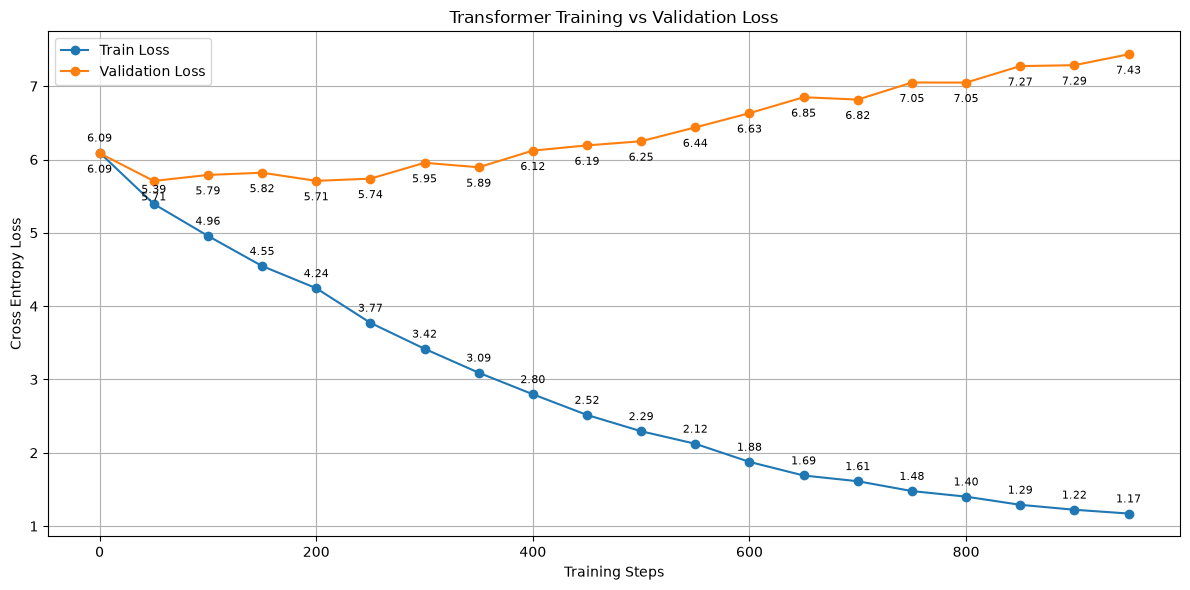

In [61]:
# 画图
plt.figure(figsize=(12, 6))
plt.plot(steps, train_losses, marker="o", label="Train Loss")
plt.plot(steps, val_losses, marker="o", label="Validation Loss")

# 标注训练集每个数据点的数值
for x, y in zip(steps, train_losses):
    plt.annotate(
        f"{y:.2f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

# 标注验证集每个数据点的数值
for x, y in zip(steps, val_losses):
    plt.annotate(
        f"{y:.2f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, -14),
        ha="center",
        fontsize=8
    )

plt.xlabel("Training Steps")
plt.ylabel("Cross Entropy Loss")
plt.title("Transformer Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [78]:
@torch.no_grad()
def generate_reply(model, prompt, max_new_tokens=200):
    model.eval()

    # 将输入的对话上下文编码成数字
    ids, _ = encode_with_mask(prompt)
    
    idx = torch.tensor(
        [ids],
        dtype=torch.long
    )

    # 逐个生成新字符
    for _ in range(max_new_tokens):

        # 模型最多只能看到最近 block_size 个字符
        idx_cond = idx[-block_size:]

        # 获取模型预测
        logits = model(idx_cond)

        # 只关注最后一个位置的预测
        logits = logits[:, -1, :]

        # 将分数转换为概率
        probs = F.softmax(logits, dim=-1)

        # 抽取下一个字符
        idx_next = torch.multinomial(probs, num_samples=1)

        # 拼接到已有文本后面
        idx = torch.cat((idx, idx_next), dim=1)

        # 解码当前文本，检查是否生成了结束标记
        result = decode(idx[0].tolist())

        if "<END>" in result[len(prompt):]:
            break

    # 只返回模型新生成的内容
    result = decode(idx[0].tolist())
    return result[len(prompt):]

In [83]:
print("user：我想请教一个问题：类是什么意思？")
print("assistant：", generate_reply(
    model,
    "我想请教一个问题：类是什么意思？"
))

user：我想请教一个问题：类是什么意思？


IndexError: index out of range in self